# Agent-to-Agent (A2A) Protocol

The Agent-to-Agent (A2A) protocol is an open standard for enabling autonomous AI agents built on different frameworks to communicate, discover each other, and collaborate on tasks. This course covers A2A architecture, building agents across frameworks (OpenAI Agents SDK, LangGraph, CrewAI), orchestration patterns, and production deployment.

## Table of Contents

- [Module 01: A2A Protocol Architecture and Core Concepts](#module-01-a2a-protocol-architecture-and-core-concepts)
- [Module 02: Building A2A Agents Across Frameworks](#module-02-building-a2a-agents-across-frameworks)
- [Module 03: Orchestration Patterns and Multi-Agent Workflows](#module-03-orchestration-patterns-and-multi-agent-workflows)
- [Module 04: Security, Testing, and Production Deployment](#module-04-security-testing-and-production-deployment)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: A2A Protocol Architecture and Core Concepts

_Introduces the problem A2A solves, agent cards, capability discovery, and the full task lifecycle._

### The Problem: Multi-Framework Agent Integration

Modern AI systems often combine agents built with different frameworks — LangGraph, CrewAI, OpenAI Agents SDK — each running independently. Without a standard protocol, integrating them requires writing custom HTTP glue code for every agent pair.


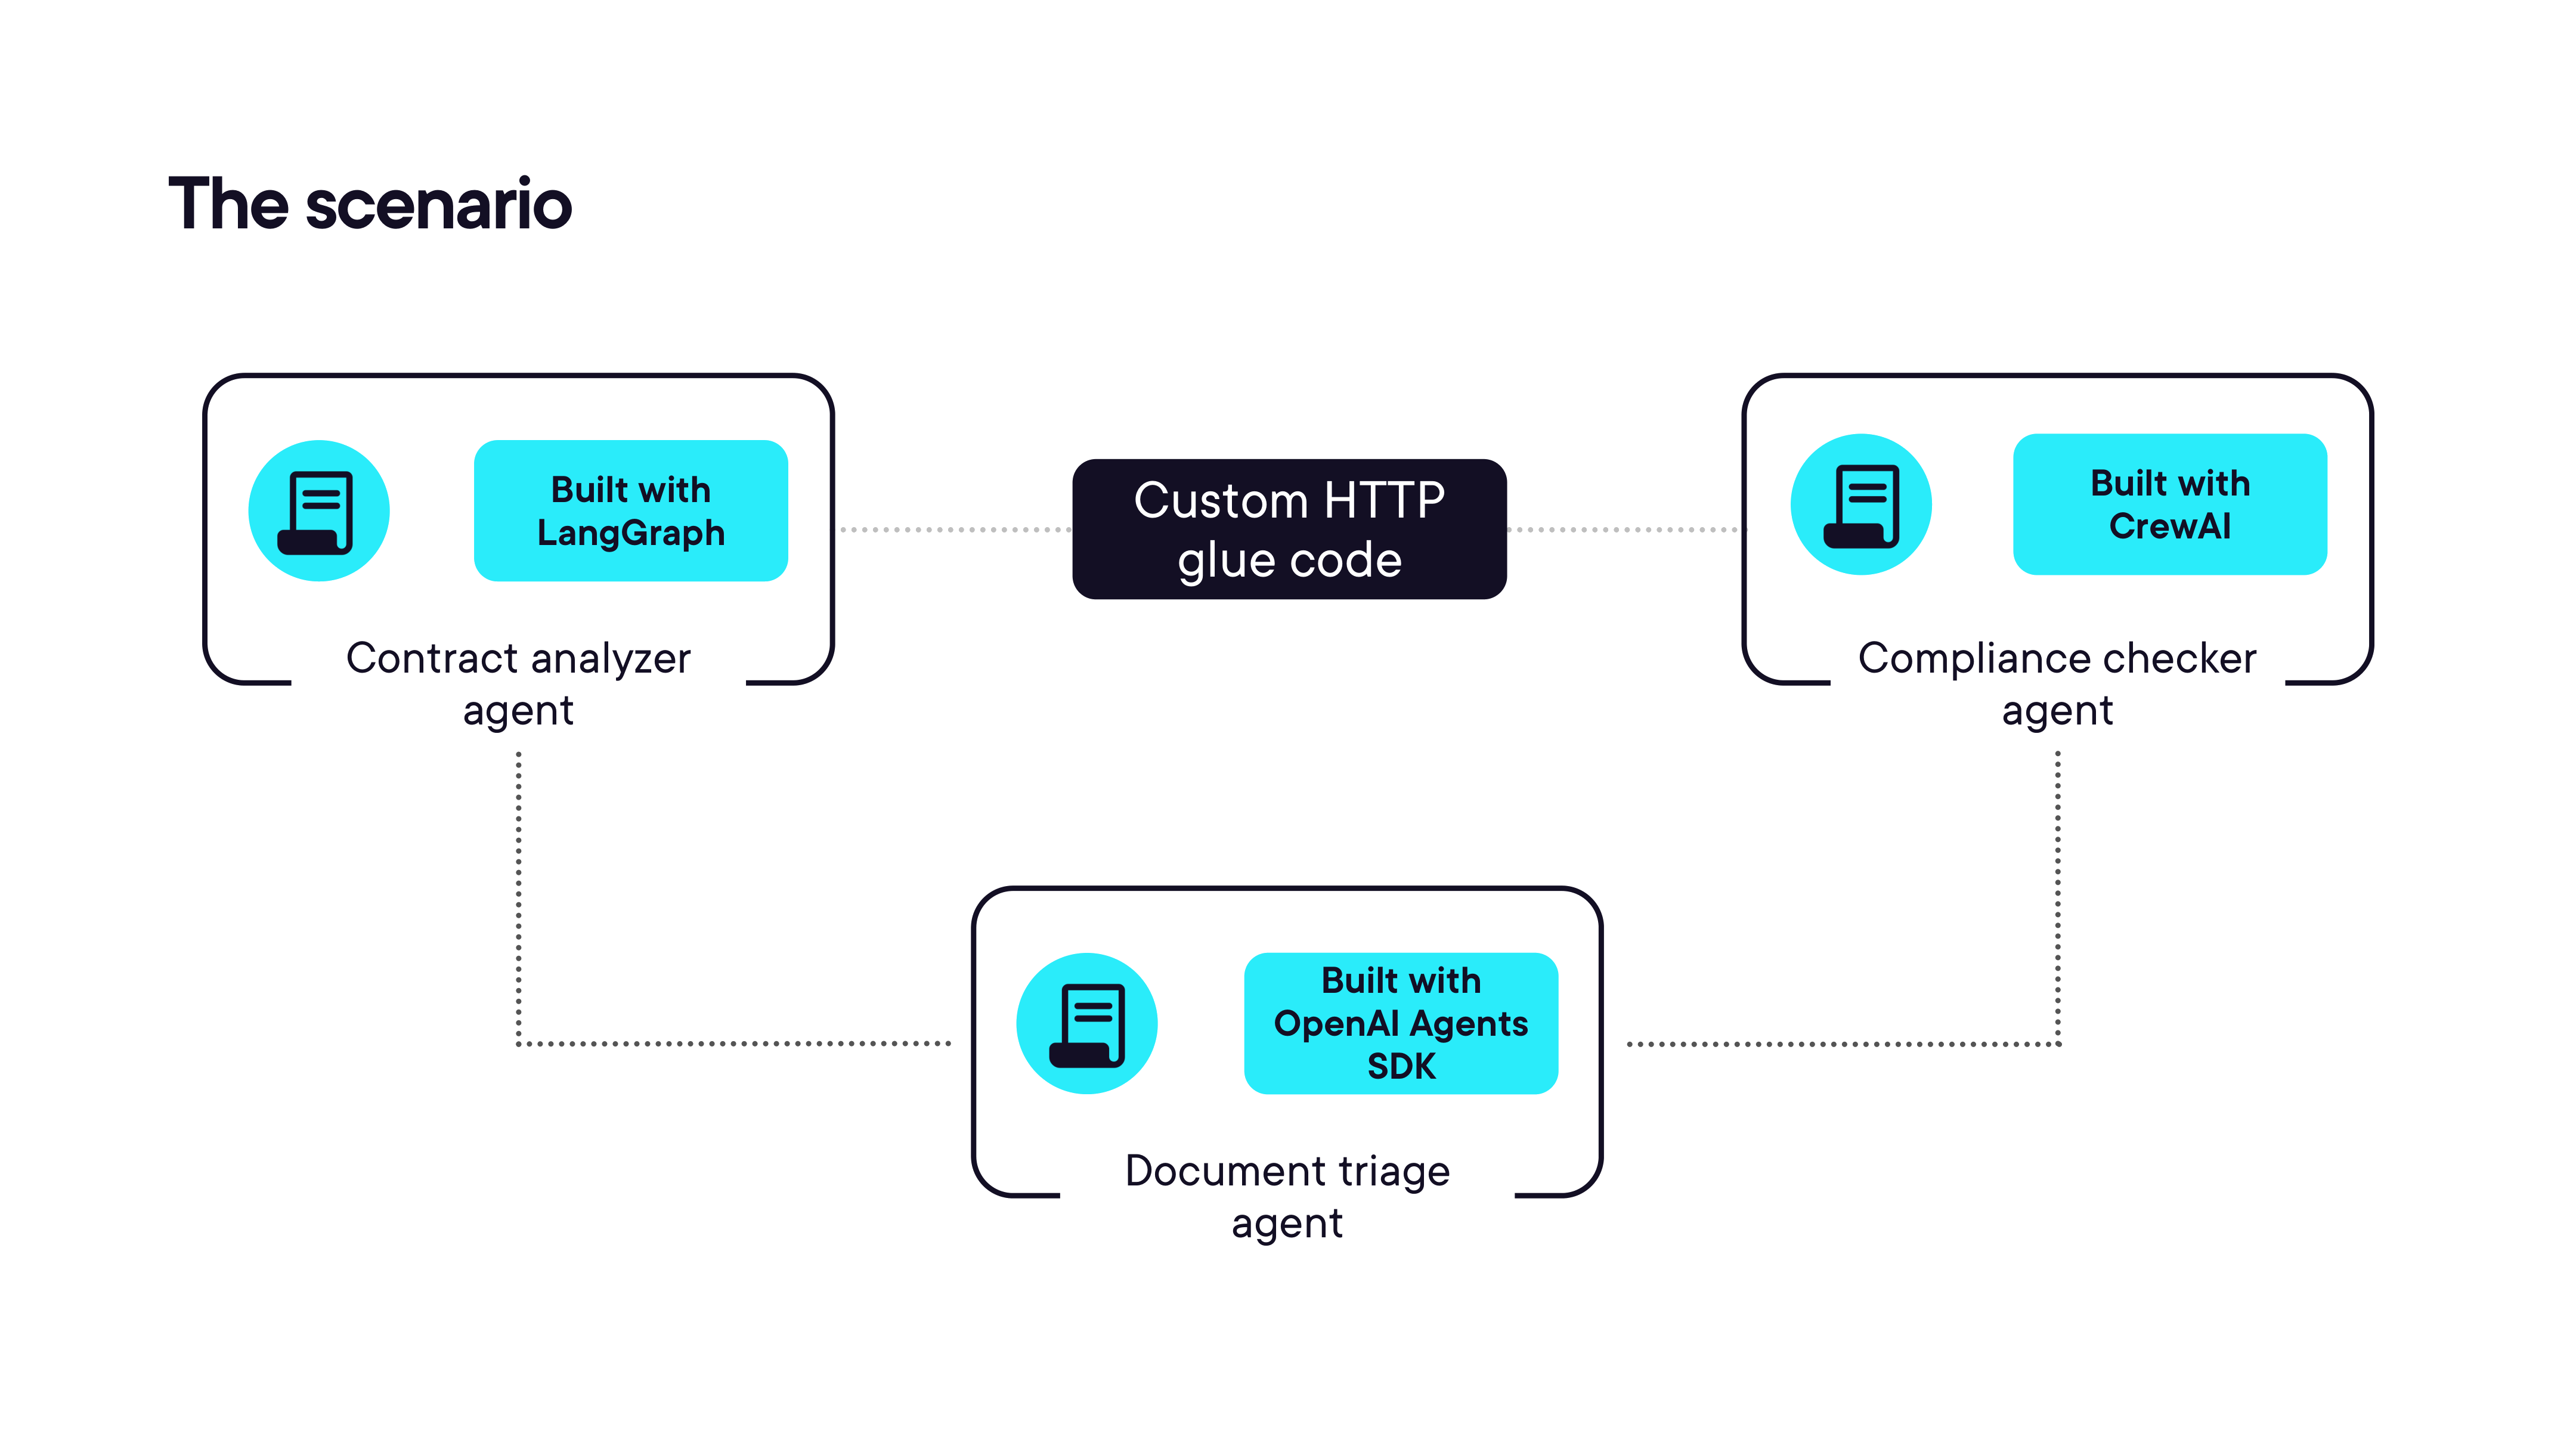

In [2]:
render_diagram(Path("assets/01-multi-agent-scenario.png"))

**The glue code problem:**

- **Custom handlers** — you write HTTP endpoints for each agent pair; the more agents, the more endpoints
- **Fragile contracts** — change one agent's response format and every integration that calls it breaks
- **No discovery** — each agent needs to know the exact URL and payload shape of every other agent

### A2A and MCP: Complementary Protocols

| Protocol | Role |
|----------|------|
| **MCP** | Connects agents to tools and data — your agent calls a database, reads a file, or hits an API through MCP |
| **A2A** | Connects agents to each other — your agent delegates a task to a peer agent and gets structured results back |

MCP handles the tool layer; A2A handles the agent-to-agent layer. Together they form a complete agentic stack.

### A2A Origins and Governance

- **April 2025** — Launched by Google
- **June 2025** — Donated to the Linux Foundation
- **Broad industry backing** — 150+ organizations including AWS, Microsoft, Salesforce, SAP, and IBM
- **August 2025** — IBM's Agent Communication Protocol (ACP) merged into A2A

### What This Course Builds

- **Three agents** — OpenAI Agents SDK, LangGraph, and CrewAI, each wrapped as an A2A server
- **Orchestrated workflows** — an orchestrator that routes tasks, delegates to workers, and handles failures
- **Secured and deployed** — token-based auth, distributed tracing, and production deployment via Agent Stack

### Agent Cards and Capability Discovery

#### The Agent Card

An **agent card** is a JSON document published at a well-known endpoint that describes who an agent is, what it can do, and how to talk to it. Every A2A agent publishes this at `/.well-known/agent-card.json`.

```json
{
  "name": "ContractReviewAgent",
  "description": "Analyzes contracts and flags risk clauses",
  "version": "1.0.0",
  "defaultInputModes": ["text"],
  "defaultOutputModes": ["text"],
  "capabilities": {
    "streaming": false
  },
  "supportedInterfaces": [
    {
      "protocolBinding": "JSONRPC",
      "url": "http://localhost:9999"
    }
  ],
  "skills": [
    {
      "id": "contract-analysis",
      "name": "Contract Analysis",
      "description": "Analyzes contract text for risk clauses",
      "tags": ["contract", "legal", "risk"],
      "examples": ["Review this NDA for non-compete clauses"]
    }
  ]
}
```

#### How Discovery Works


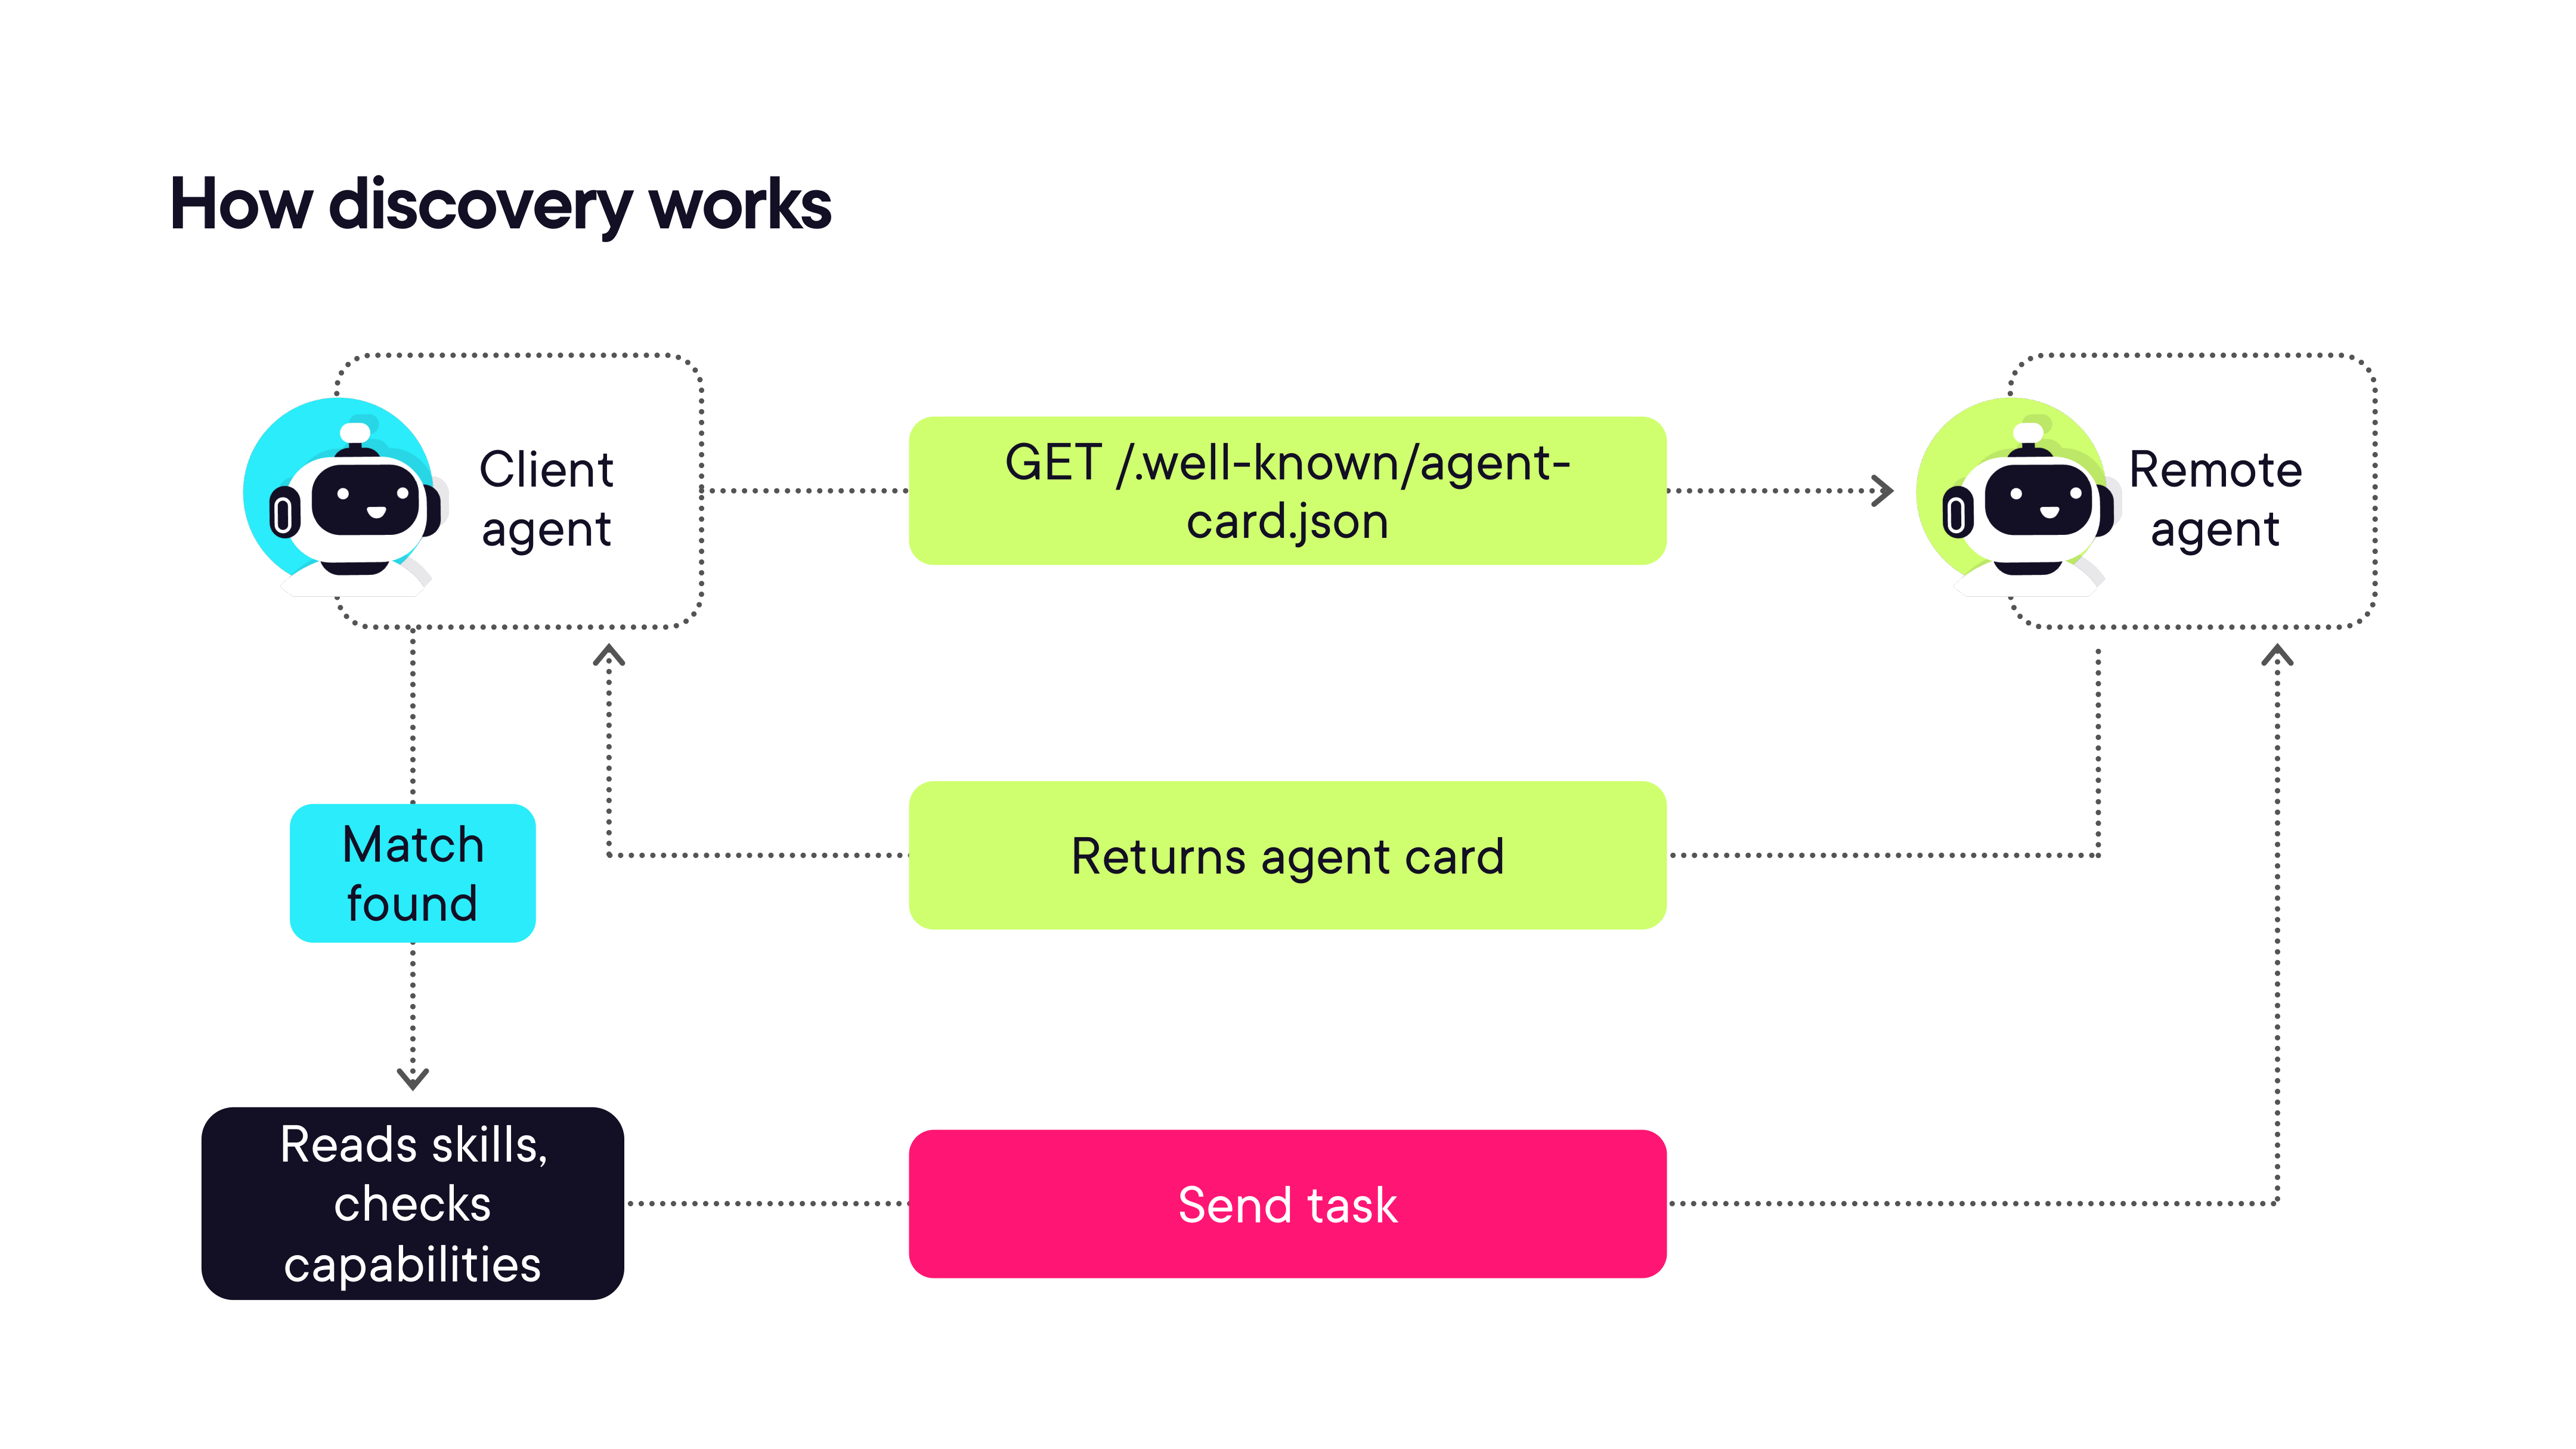

In [3]:
render_diagram(Path("assets/02-agent-card-discovery-flow.png"))

#### Capability Negotiation

- **Input/output negotiation** — the client checks `defaultInputModes` and `defaultOutputModes` to know if conversions need to happen
- **Streaming negotiation** — the client checks `capabilities.streaming` to receive progress updates as the task runs

### Demo: Viewing a Live Agent Card

Fetch an agent card from a running A2A server — see [`01-a2a-agent-demos/Module1/`](01-a2a-agent-demos/Module1/) for the full example.

```bash
curl http://localhost:9999/.well-known/agent-card.json
```

### Tasks, Messages, and the A2A Lifecycle

#### The Task Object

A task is the fundamental unit of work in A2A. It tracks state across a multi-turn conversation between a client and a remote agent.

```json
{
  "id": "task-001",
  "contextId": "session-abc-123",
  "status": {
    "state": "submitted"
  },
  "messages": [
    {
      "role": "user",
      "parts": [
        {
          "type": "text",
          "text": "Review this contract for non-compete clauses and flag any risk areas."
        }
      ]
    }
  ]
}
```

#### Task Lifecycle State Machine


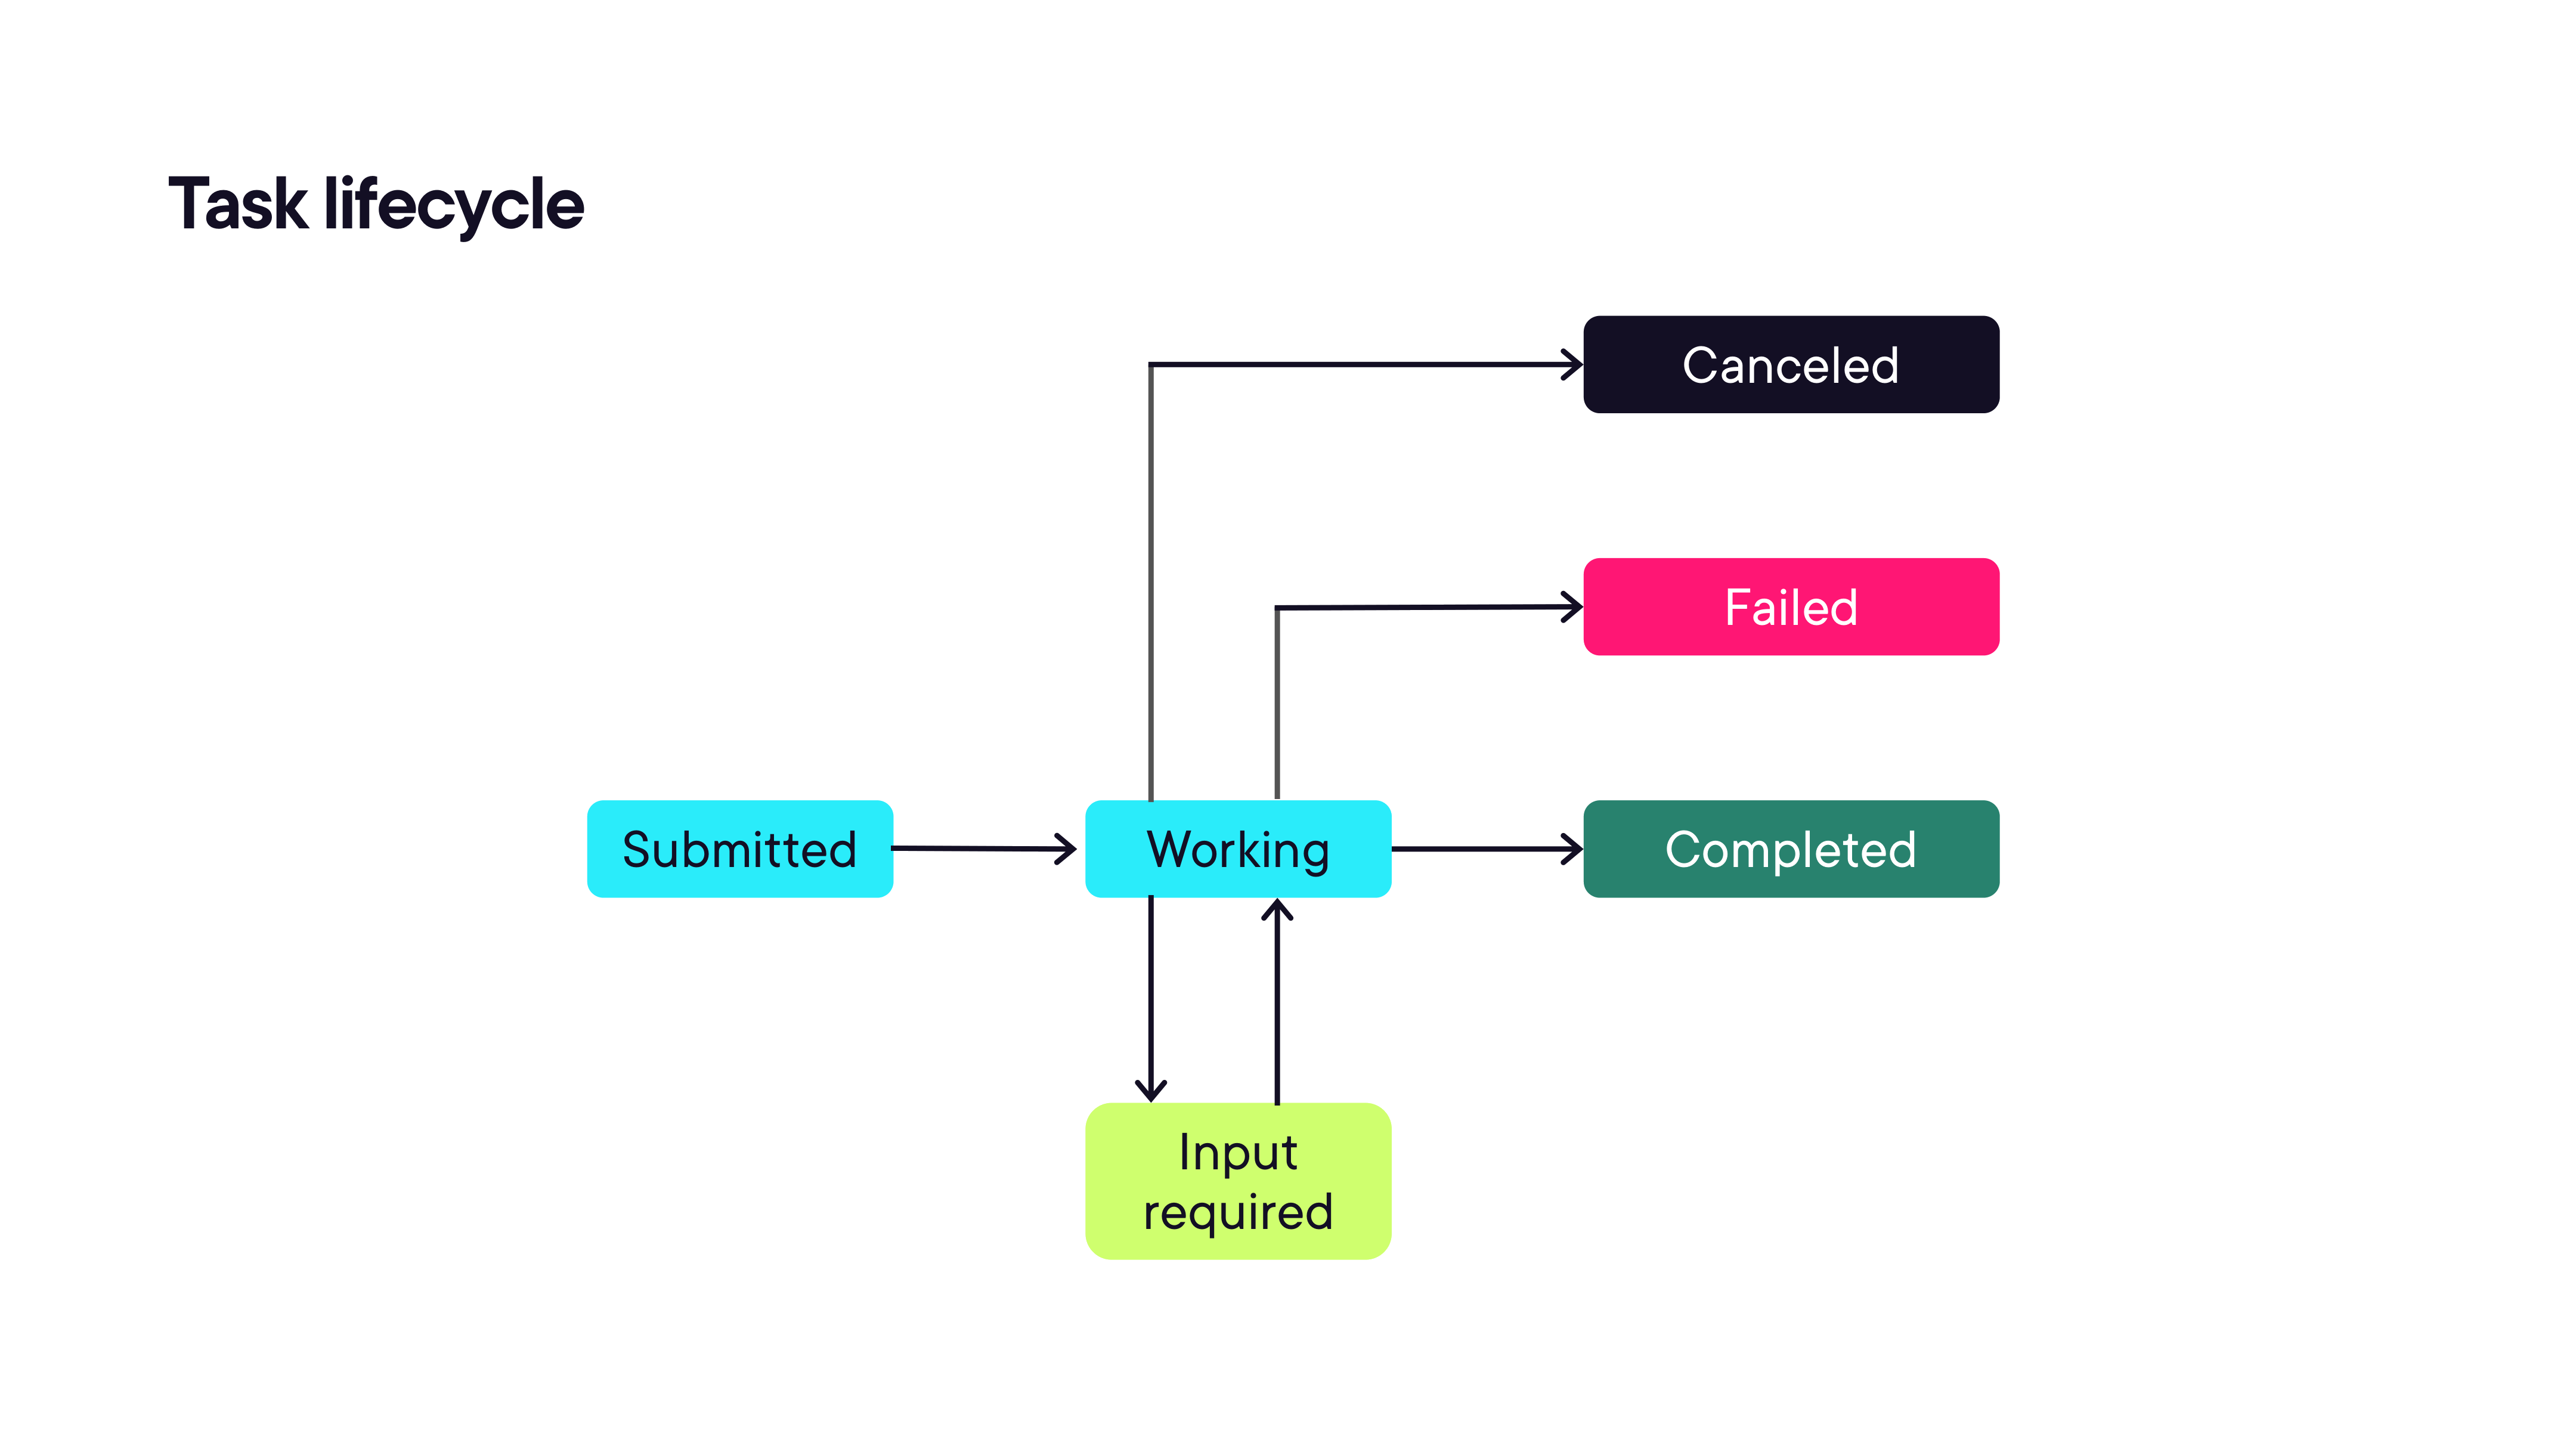

In [4]:
render_diagram(Path("assets/03-task-lifecycle.png"))

States:
- **Submitted** → task received, not yet processing
- **Working** → agent is actively processing
- **Input required** ↔ **Working** — agent may pause to ask clarifying questions mid-task
- **Completed** — task finished successfully
- **Failed** — terminal error
- **Canceled** — client or agent canceled the task

#### Messages and Parts

Each message has a **role** (`user` or `agent`) and an array of **parts**. Parts are typed content blocks — they can be text, files, structured data, or binary content.

#### Streaming and Artifacts

- **Streaming** — for long-running tasks, the agent streams status updates and partial results using SSE (Server-Sent Events)
- **Artifacts** — an artifact contains one or more parts representing the final output of a completed task

### A2A vs. Tool Calling (MCP)

| | **Tool calling (MCP)** | **Agent delegation (A2A)** |
|---|---|---|
| **What you are calling** | A function with structured input/output | An autonomous peer that reasons and plans |
| **Interaction** | Single request, single response | Multi-turn conversation with status updates |
| **Discovery** | Tool manifests within a server | Agent cards at well-known endpoints |
| **Follow-ups** | Not supported | Agent can ask clarifying questions mid-task |
| **Streaming** | Limited | Built in with SSE |

**Summary:** A2A models agents as autonomous peers with their own reasoning loops, not just callable functions. The task lifecycle and multi-turn conversation model are the key differentiators.

## Module 02: Building A2A Agents Across Frameworks

_Wraps three different agent frameworks as A2A servers and shows how a unified client can discover and call all three._

### The Three Agents

| Agent | Framework | Port | Responsibility |
|-------|-----------|------|---------------|
| Document triage agent | OpenAI Agents SDK | 9999 | Reads a document description and classifies it as contract, invoice, or compliance filing |
| Contract review agent | LangGraph | 9998 | Analyzes contract text and flags risk clauses |
| Compliance checker agent | CrewAI | 9997 | Checks documents against regulatory requirements |

### Building an A2A Agent with OpenAI Agents SDK

Each agent is wrapped the same way regardless of framework:
1. Define the agent's core logic (using the framework's native API)
2. Create an A2A server that publishes an agent card at `/.well-known/agent-card.json`
3. Implement the JSON-RPC task handler that receives tasks, runs the agent, and returns results

### Demo: Document Triage Agent (OpenAI Agents SDK)

See [`01-a2a-agent-demos/Module2/clip-1-1building-an-a2a-agent-with-openai/`](01-a2a-agent-demos/Module2/clip-1-1building-an-a2a-agent-with-openai/) for begin/end states.

### Building an A2A Agent with LangGraph

LangGraph agents use a stateful graph structure. The A2A wrapper receives a task, feeds it into the graph's state, runs the graph, and returns the final state as an artifact.

### Demo: Contract Review Agent (LangGraph)

See [`01-a2a-agent-demos/Module2/clip-2-building-an-a2a-agent-with-langgraph/`](01-a2a-agent-demos/Module2/clip-2-building-an-a2a-agent-with-langgraph/).

### Building an A2A Agent with CrewAI

CrewAI agents are defined as crews with roles and goals. The A2A wrapper maps task messages to crew inputs and crew outputs to A2A artifacts.

### Demo: Compliance Checker Agent (CrewAI)

See [`01-a2a-agent-demos/Module2/clip-3-building-an-a2a-agent-with-crewai/`](01-a2a-agent-demos/Module2/clip-3-building-an-a2a-agent-with-crewai/).

### Discovering and Calling All Three Agents

A unified A2A client discovers each agent by fetching its card, reads the skills and capabilities, and routes tasks to the appropriate agent.


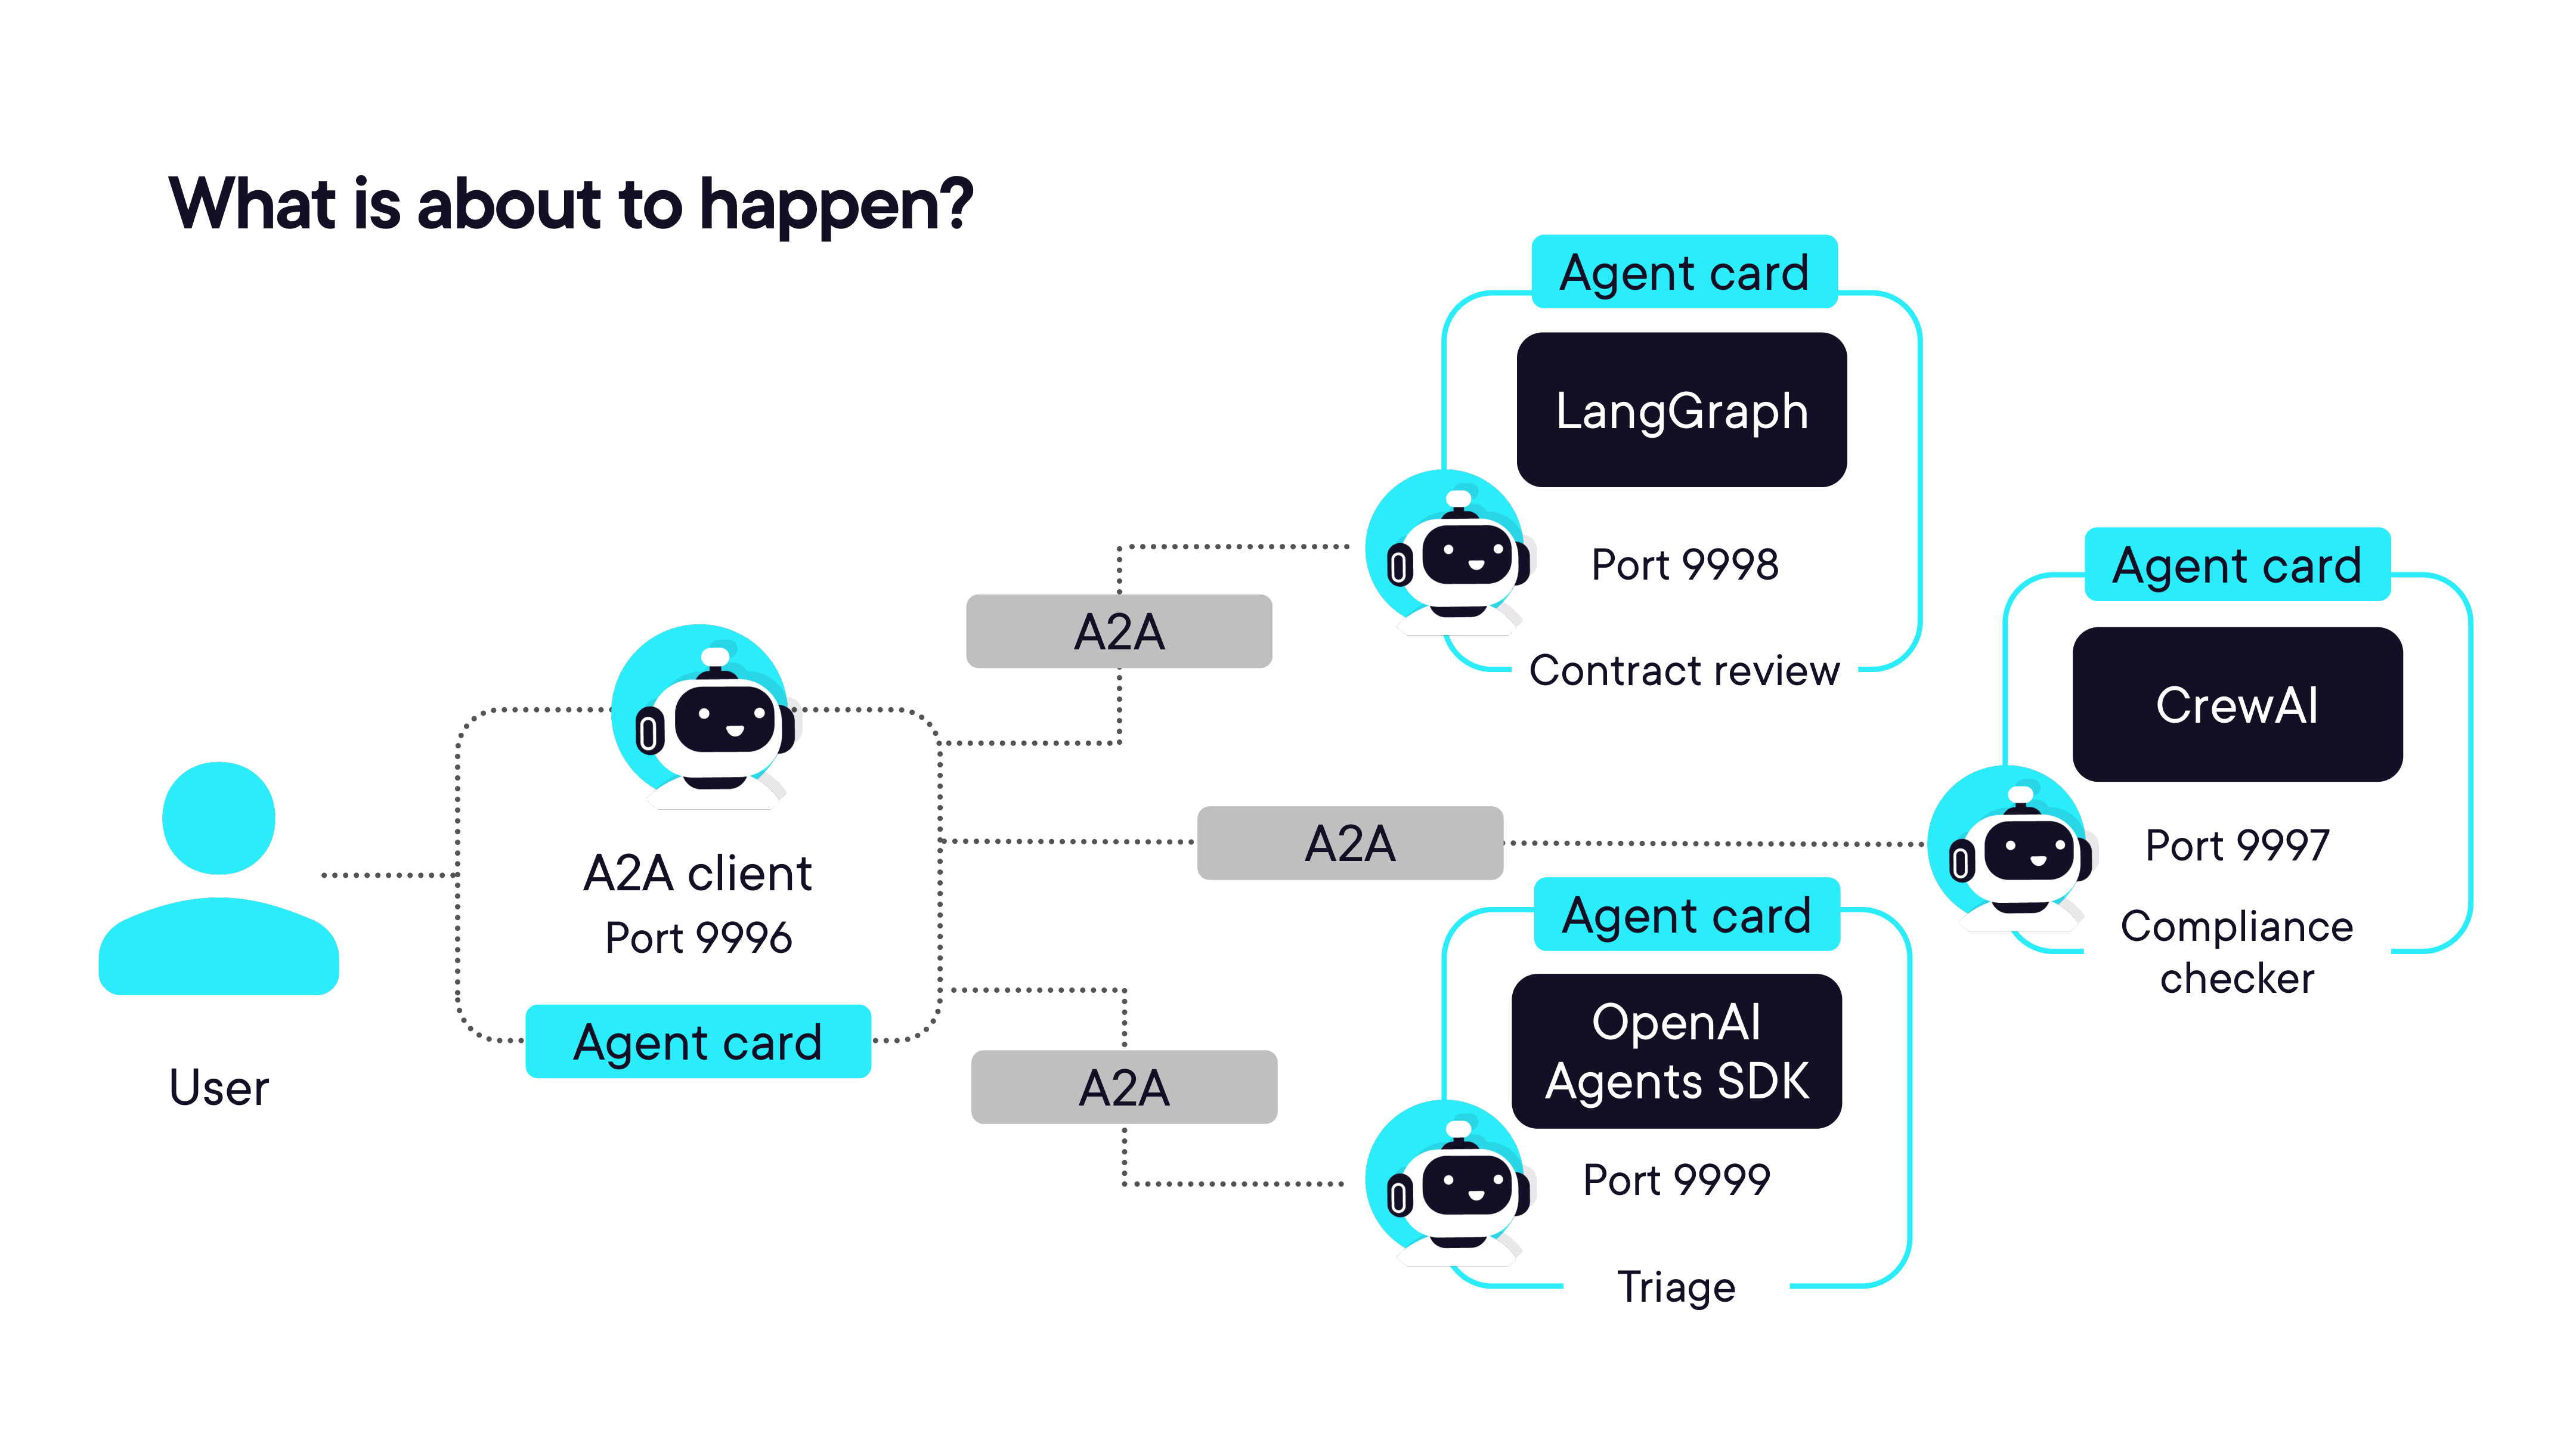

In [5]:
render_diagram(Path("assets/04-unified-a2a-client.png"))

### Demo: Unified A2A Client

See [`01-a2a-agent-demos/Module2/clip-4-discovering-and-calling-all-three-agents/`](01-a2a-agent-demos/Module2/clip-4-discovering-and-calling-all-three-agents/).

The client flow:
1. Fetch agent card from each of the three agents
2. Parse `skills` to understand what each can do
3. Route the user's document to the appropriate agent(s)
4. Collect and present results

## Module 03: Orchestration Patterns and Multi-Agent Workflows

_Implements the orchestrator-worker pattern, hierarchical delegation, and failure handling with retries._

### The Orchestrator-Worker Pattern


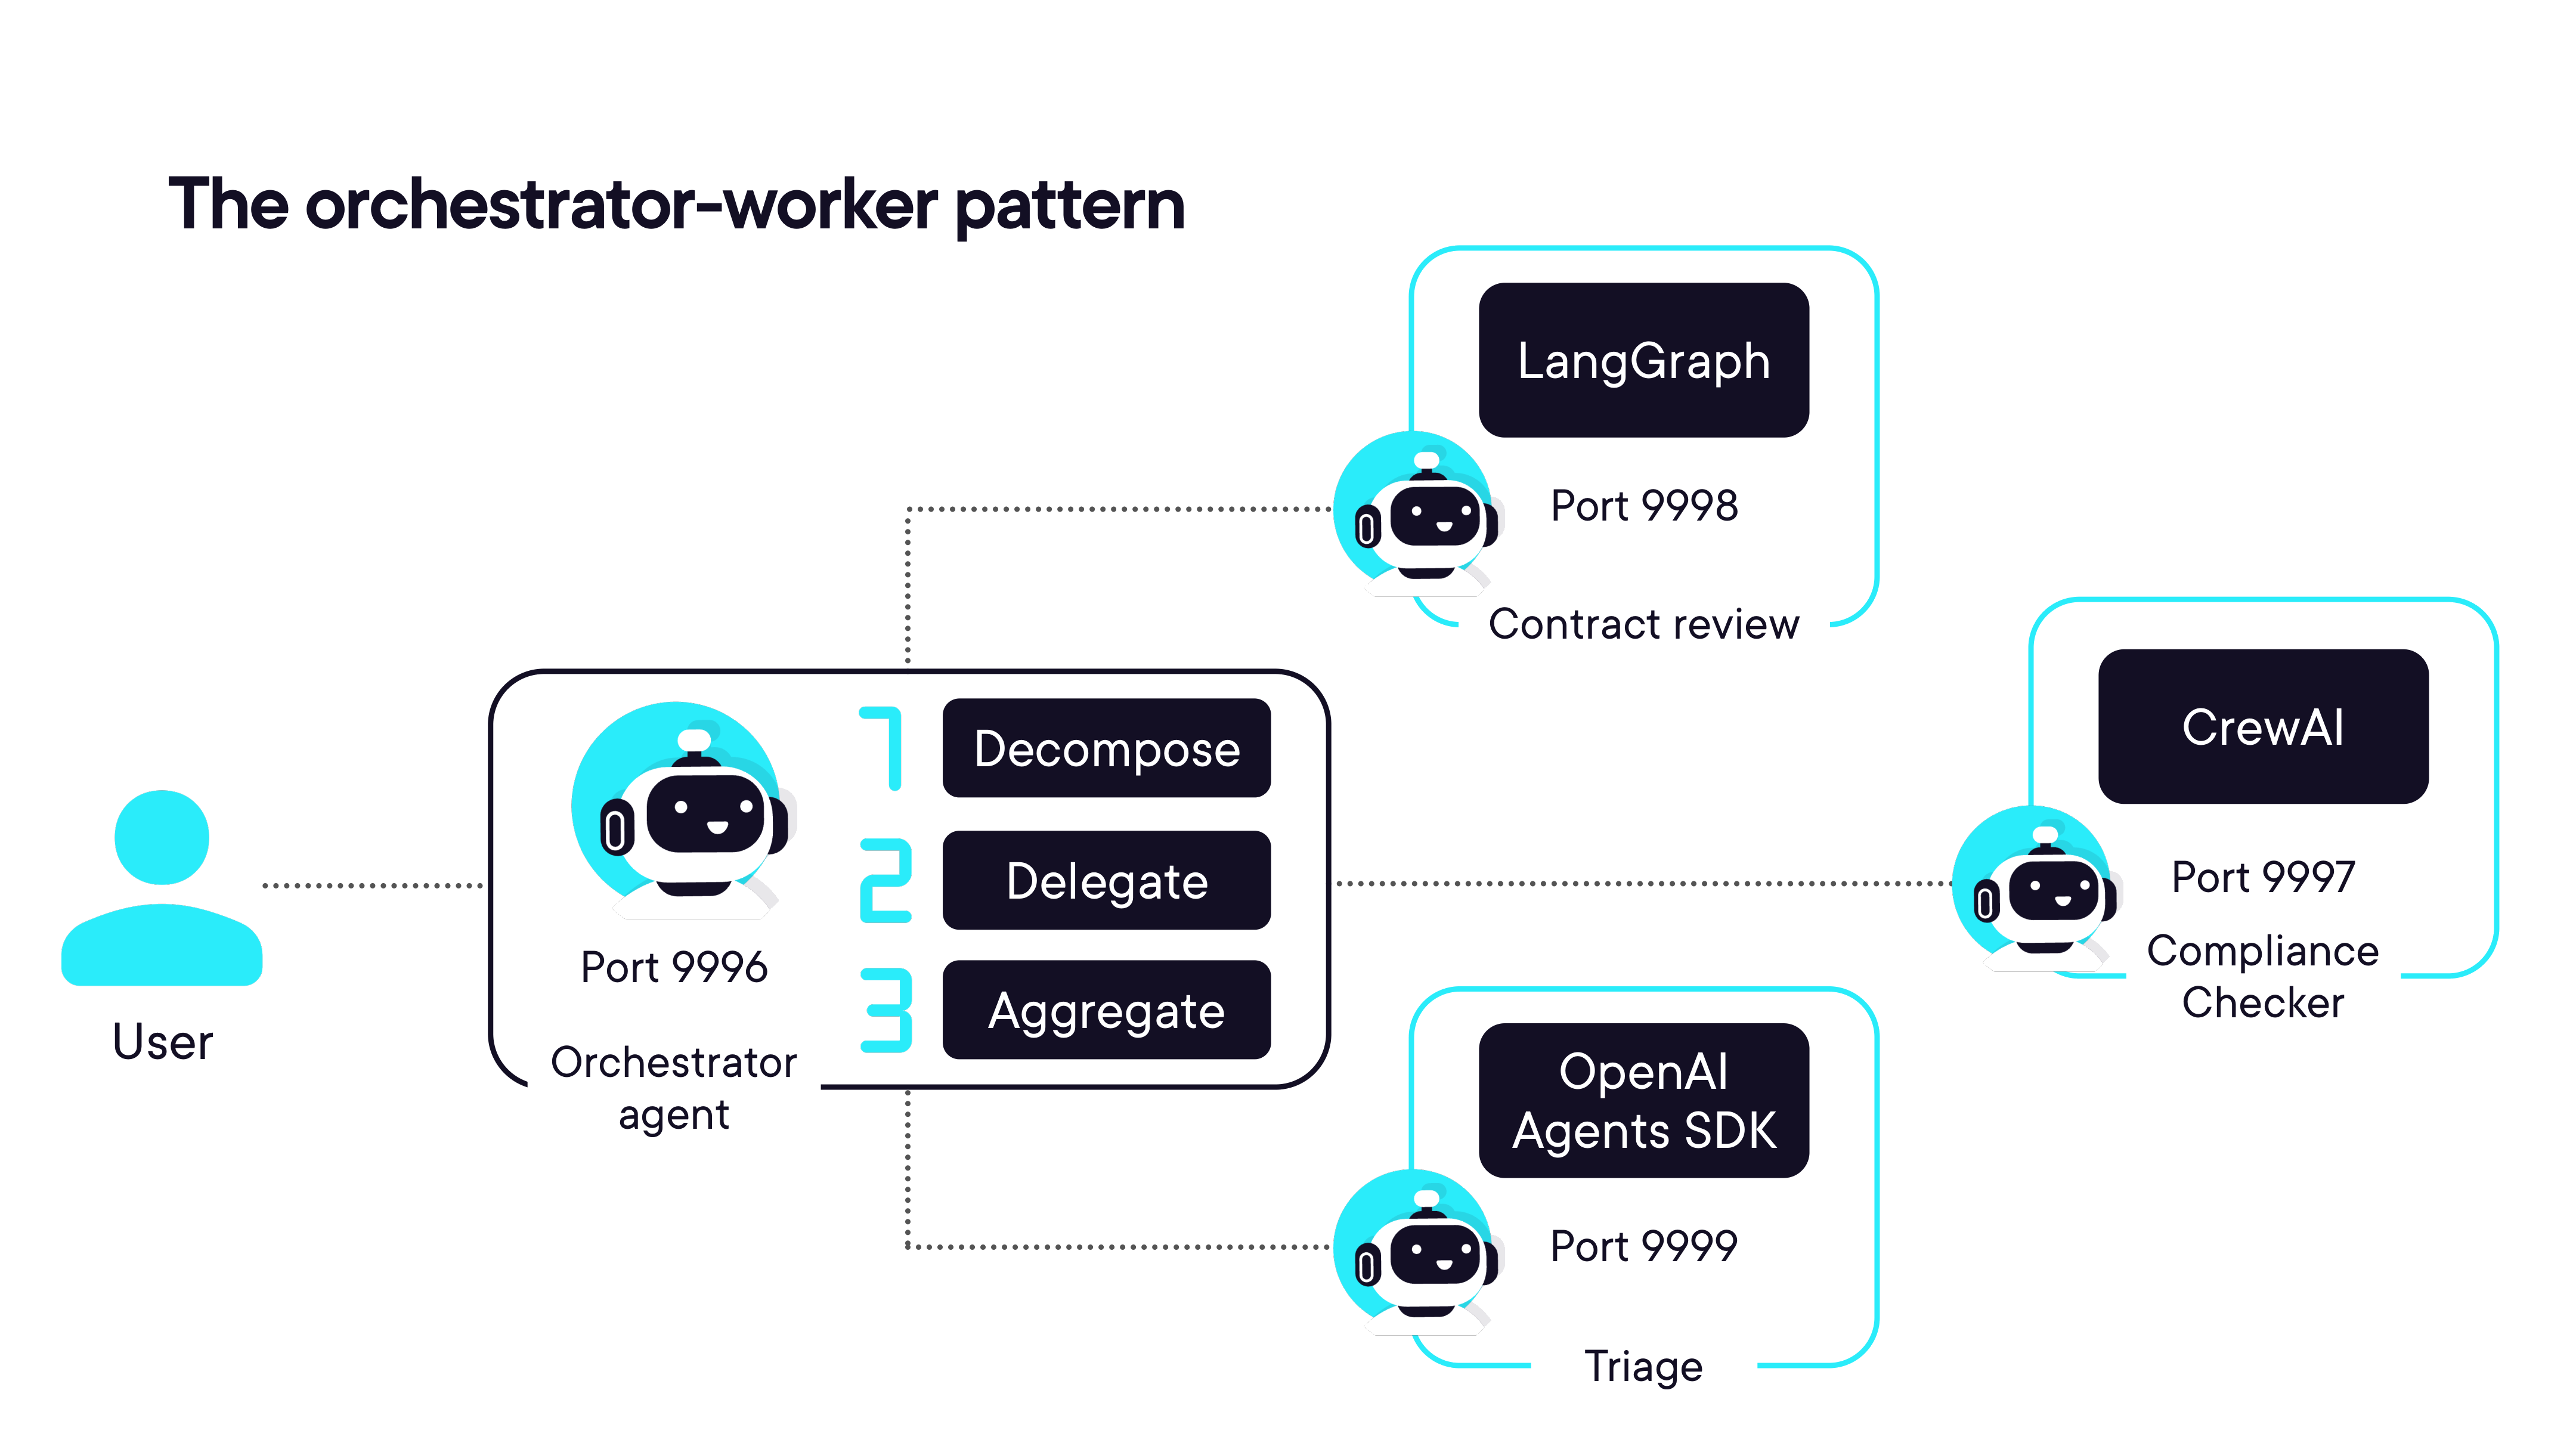

In [6]:
render_diagram(Path("assets/05-orchestrator-worker-pattern.png"))

The orchestrator agent (port 9996) receives a task from the user and applies a three-step pattern:

1. **Decompose** — break the task into sub-tasks suitable for each worker agent
2. **Delegate** — send each sub-task to the appropriate worker via A2A
3. **Aggregate** — collect worker results and combine them into a unified response

### Demo: Orchestrator Agent with Task Decomposition

See [`01-a2a-agent-demos/Module3/clip-1-implementing-orchestrator-worker-pattern/`](01-a2a-agent-demos/Module3/clip-1-implementing-orchestrator-worker-pattern/).

### Hierarchical Delegation


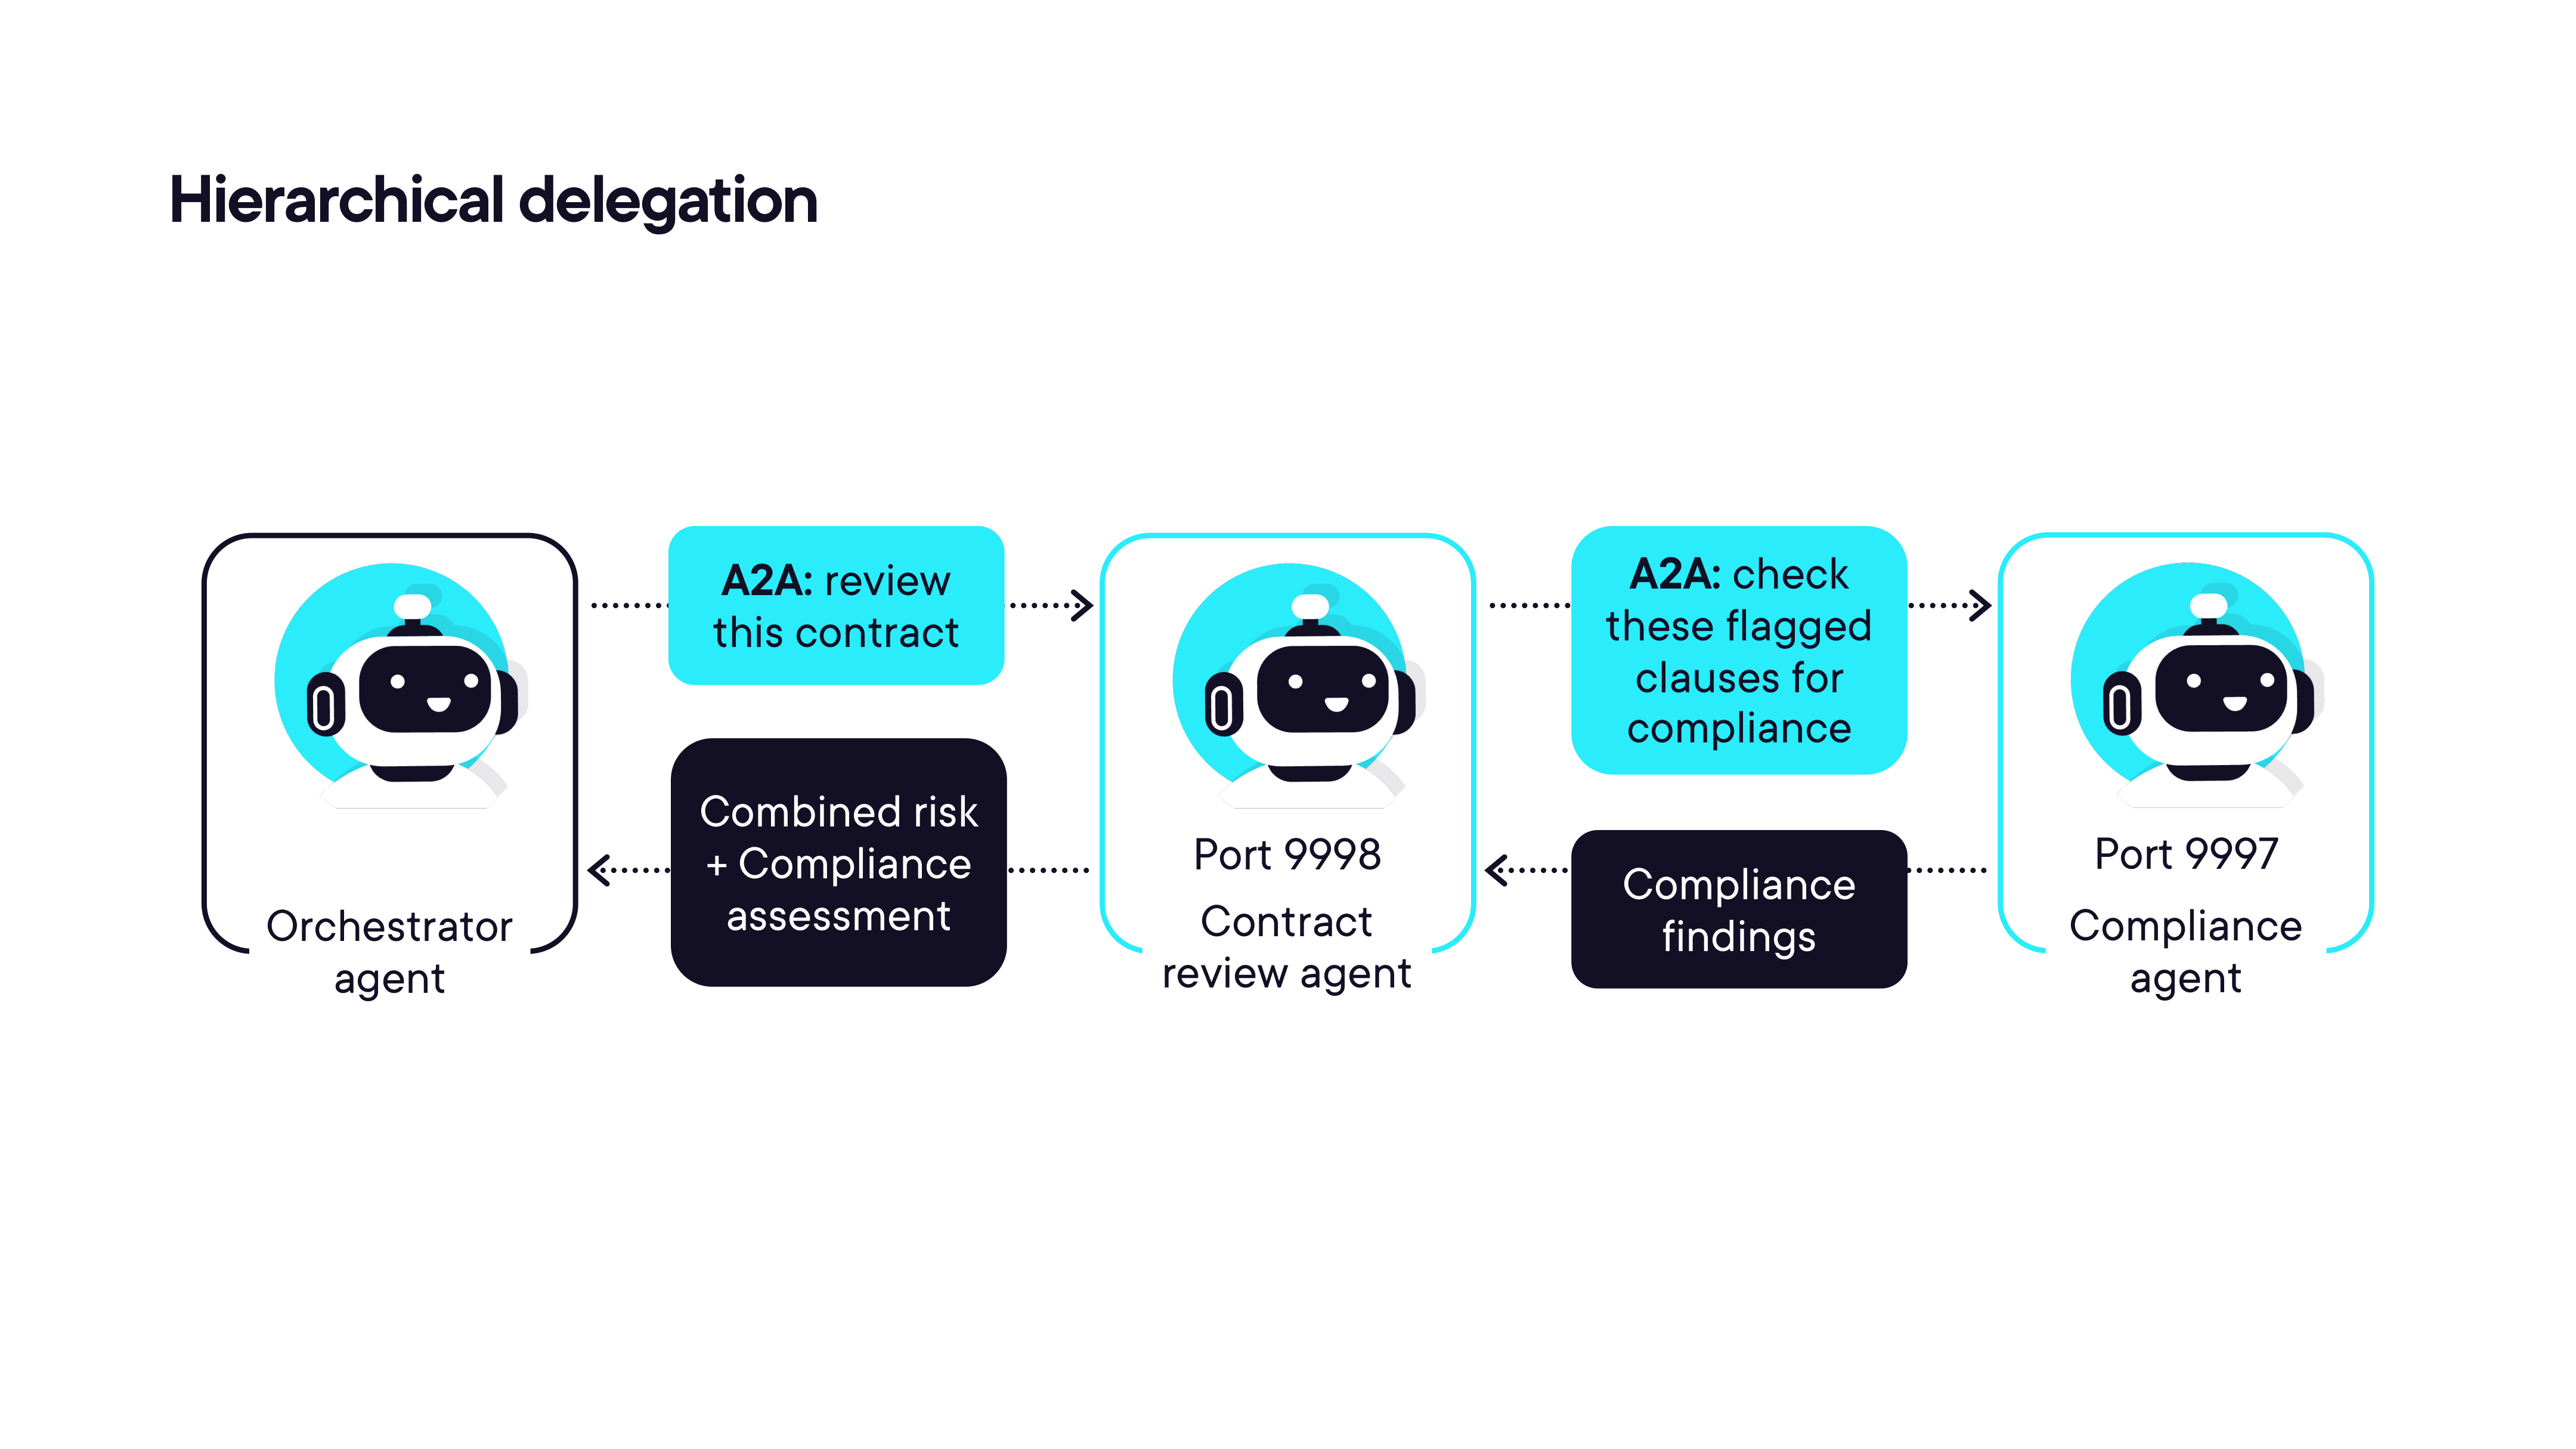

In [7]:
render_diagram(Path("assets/06-hierarchical-delegation.png"))

In hierarchical delegation, a worker agent can itself act as a client to downstream agents. In this example:

1. Orchestrator sends `A2A: review this contract` → Contract review agent (port 9998)
2. Contract review agent sends `A2A: check these flagged clauses for compliance` → Compliance agent (port 9997)
3. Compliance agent returns **compliance findings** → Contract review agent
4. Contract review agent returns **combined risk + compliance assessment** → Orchestrator

This allows deep pipelines without the orchestrator needing to know the internal structure of each worker's workflow.

### Demo: Contract Review Agent with Hierarchical Delegation

See [`01-a2a-agent-demos/Module3/clip-2-implementing-dynamic-routing-and-hierarchical-delegation/`](01-a2a-agent-demos/Module3/clip-2-implementing-dynamic-routing-and-hierarchical-delegation/).

### Handling Failures and Retries

#### What Can Go Wrong

- **Agent unavailable** — the remote agent is down or unreachable; the connection fails before any task starts
- **Timeout** — the remote agent accepts the task but takes too long to respond; the client gives up waiting
- **Partial failure** — in a multi-agent request, some agents succeed and others fail; the orchestrator has partial results

#### Resilience Strategies

- **Retry with backoff** — retry transient failures (unavailable, timeout) with exponential backoff
- **Graceful degradation** — when an agent fails, return partial results from the agents that succeeded rather than failing the whole workflow
- **Circuit breaking** — stop sending to a consistently failing agent to avoid cascading delays

### Demo: Retry Logic and Graceful Degradation

See [`01-a2a-agent-demos/Module3/clip-3-handling-failures-and-retries/`](01-a2a-agent-demos/Module3/clip-3-handling-failures-and-retries/).

## Module 04: Security, Testing, and Production Deployment

_Covers the A2A security model, testing with A2A Inspector, and production deployment with Agent Stack._

### Securing Authentication, Authorization, and Trust

#### A2A Security Model

- **Authentication** — clients read agent cards before connecting and attach credentials to every request
- **Authorization** — the orchestrator controls what each worker can access using scoped tokens
- **Trust boundaries** — every agent outside your direct control is untrusted input; never execute code from agent responses

#### Security Threats in A2A

- **Prompt injection** — a malicious task payload manipulates the agent's LLM into performing unintended actions
- **Task hijacking** — an unauthorized agent intercepts or redirects tasks meant for a different agent
- **Privilege escalation** — a subagent uses its delegated permissions to access resources beyond its scope

### Demo: Adding Auth to an Agent Card

See [`01-a2a-agent-demos/Module4/clip-1-securing-authentication-auhtorization-trust/`](01-a2a-agent-demos/Module4/clip-1-securing-authentication-auhtorization-trust/).

### Testing and Debugging with A2A Inspector

A2A Inspector is a tool for validating agent compliance with the A2A specification.

#### Agent Card Conformance
- Does the card have all required fields?
- Do skills have descriptions and examples?
- Does the supported interface URL match where the agent is running?

#### Task Lifecycle Conformance
- Does the agent transition through the correct states (submitted → working → completed)?
- Does the agent produce an artifact with the expected content?
- Does the agent handle bad or missing input without crashing?

#### Protocol Compliance
- Are JSON-RPC messages well-formed?
- Does the agent return proper error codes?
- Does streaming work if declared in capabilities?

#### Running A2A Inspector

```bash
git clone https://github.com/a2aproject/a2a-inspector.git
cd a2a-inspector
docker build -t a2a-inspector .
docker run -d --network host --name a2a-inspector a2a-inspector
```

### Demo: A2A Inspector

See [`01-a2a-agent-demos/Module4/clip-2-testing-debugging-with-a2a-inspector/`](01-a2a-agent-demos/Module4/clip-2-testing-debugging-with-a2a-inspector/).

### Demo: Protocol Tests with pytest

```python
# Example from test_protocol.py
def test_agent_card_conformance(agent_url):
    response = requests.get(f"{agent_url}/.well-known/agent-card.json")
    card = response.json()
    assert "name" in card
    assert "skills" in card
    assert len(card["skills"]) > 0
    for skill in card["skills"]:
        assert "description" in skill
        assert "examples" in skill
```

### Deploying to Production with Agent Stack

**Agent Stack** (https://agentstack.beeai.dev/stable/introduction/quickstart) is a self-hostable runtime for A2A agents.

#### What Agent Stack Provides

| Capability | Detail |
|-----------|--------|
| **Agent runtime** | Self-hostable server with agents running as managed services with health monitoring |
| **Infrastructure** | LLM routing (15+ providers), vector storage, file handling, and secrets management out of the box |
| **Framework agnostic** | Agents are exposed as A2A-compatible services automatically |
| **A2A native** | Built on the A2A protocol — handles runtime service requests and agent-to-agent communication |

### Demo: Install Agent Stack

See [`01-a2a-agent-demos/Module4/clip-3-deploying-to-production-with-agent-stack/`](01-a2a-agent-demos/Module4/clip-3-deploying-to-production-with-agent-stack/).

### Versioning and Rolling Deployments

- **Agent versioning** — the `version` field on the agent card tracks changes
- **Rolling deployments** — Agent Stack handles this through container versioning and the agent registry

### Production Readiness Checklist

- [ ] Authentication configured on all agents
- [ ] Audit logging enabled
- [ ] Protocol testing passing (A2A Inspector + pytest)
- [ ] Containerized deployment
- [ ] Health monitoring active
- [ ] Versioning strategy defined